In [ ]:
from square import *
import qibo
from qibo import Circuit, gates, set_backend


set_backend("qibojit", platform="cuda")

[Qibo 0.3.5|INFO|2026-10-09 16:31:54]: Using qibojit (numba) backend on /CPU:0


## Test

In [2]:
m = 3
n = 2*m
num_qubits = 2*n + 1

sq = Square(m, method='aqft', delta = n, parallel = False)

circ = Circuit(num_qubits)
circ.add(sq.on_qubits(*range(num_qubits)))
circ.add(gates.M(*range(num_qubits)))

MeasurementResult(qubits=(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12), nshots=None)

In [3]:
res = circ(nshots=1)
samples = res.samples()[0]
print(samples)

[0 0 0 0 0 0 0 0 0 0 0 0 0]


In [4]:
m = 3
n = 2*m
num_qubits = 2*n + 1

sq = Square(m, method = 'aqft', delta = n, parallel = False)

circ = Circuit(num_qubits)
#circ.add(gates.X(0))
circ.add(gates.X(1))
circ.add(gates.X(2))
circ.add(sq.on_qubits(*range(num_qubits)))
circ.add(gates.M(*range(num_qubits)))

res = circ(nshots=4)
samples = res.samples()
print(samples)

[[0 0 1 0 0 1 0 0 0 0 0 0 0]
 [0 0 1 0 0 1 0 0 0 0 0 0 0]
 [0 0 1 0 0 1 0 0 0 0 0 0 0]
 [0 0 1 0 0 1 0 0 0 0 0 0 0]]


## Approximate QFT squaring 

In [5]:
from square import *
import qibo
from qibo import gates

m = 4
n = 2*m
num_qubits = 2*n + 1

nshots = 10000
delta =6

avg_sr = 0

for x in range(2**m):
    sq = Square(m, method="aqft", delta = delta, parallel = False)
    circ = initialize_square(x, m)
    circ.add(sq.on_qubits(*range(num_qubits)))
    circ.add(gates.M(*range(num_qubits)))
    res = circ(nshots=nshots)
    samples = res.samples()
    R, F, Z = get_allocs(n)
    square_bits = [samp[R[0]:R[n-1]+1] for samp in samples]
    square_value =[sum(bit << i for i, bit in enumerate(sqbits)) for sqbits in square_bits]
    prob = sum(int(sq_val) == int(x**2) for sq_val in square_value)/nshots
    print(f'Input: {x} | Success rate: {prob:0.4f}')
    avg_sr += prob/2**m

print('==============================================')
print(f'Delta: {delta} | Avg. success rate: {avg_sr:0.4f}')
print('==============================================')


Input: 0 | Success rate: 0.9985
Input: 1 | Success rate: 0.9972
Input: 2 | Success rate: 0.9988
Input: 3 | Success rate: 0.9994
Input: 4 | Success rate: 0.9995
Input: 5 | Success rate: 0.9969
Input: 6 | Success rate: 0.9985
Input: 7 | Success rate: 0.9996
Input: 8 | Success rate: 0.9986
Input: 9 | Success rate: 0.9979
Input: 10 | Success rate: 0.9992
Input: 11 | Success rate: 0.9993
Input: 12 | Success rate: 0.9986
Input: 13 | Success rate: 0.9967
Input: 14 | Success rate: 0.9986
Input: 15 | Success rate: 0.9996
Delta: 6 | Avg. success rate: 0.9986


## Delta parameter sweep for fixed number of qubits

In [6]:
def run_sim(m, d, nshots):
    n = 2*m
    num_qubits = 2*n + 1
    avg_sr = 0

    sq = Square(m, method="aqft", delta = d)

    for x in range(2**m):
        circ = initialize_square(x, m)
        circ.add(sq.on_qubits(*range(num_qubits)))
        circ.add(gates.M(*range(num_qubits)))
        res = circ(nshots=nshots)
        samples = res.samples()
        R, F, Z = get_allocs(n)
        square_bits = [samp[R[0]:R[n-1]+1] for samp in samples]
        square_value =[sum(bit << i for i, bit in enumerate(sqbits)) for sqbits in square_bits]
        prob = sum(int(sq_val) == int(x**2) for sq_val in square_value)/nshots
        avg_sr += prob/2**m
    return avg_sr, sq

In [7]:
m = 4
nshots = 100

deltas = list(range(0, 2*m+1))
averages = []

for d in deltas:
    print(d)
    avg, _ = run_sim(m, d, nshots)
    averages.append(avg)


0
1
2
3
4
5
6
7
8


Text(0, 0.5, 'Avg. success rate for all inputs (100 shots)')

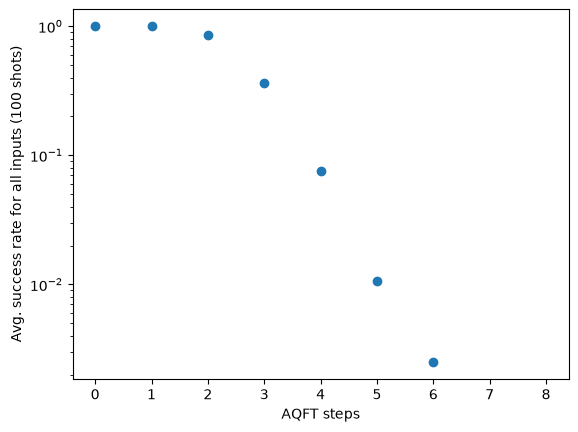

In [13]:
import matplotlib.pyplot as plt
plt.scatter(deltas, 1- np.array(averages))
plt.yscale('log')
plt.xlabel('AQFT steps')
plt.ylabel(f'Avg. success rate for all inputs ({nshots} shots)')

In [8]:
1- np.array(averages)

array([1.00000e+00, 9.95625e-01, 8.70625e-01, 3.78750e-01, 7.50000e-02,
       8.12500e-03, 6.25000e-04, 0.00000e+00, 0.00000e+00])

## Resource-error characterization

In [14]:
from tqdm import tqdm 

def delta_sweep(m, nshots):
    deltas = list(range(0, 2*m+1))
    stats = {
        'delta' : [],
        'error' : [],
        'cnot' : [],
        'toffoli' : [],
        'cu1' : [],
        'swap' : [],
        'single' : [],
        'total' :[]
    }
    for d in tqdm(deltas):
        avg, circ = run_sim(m, d, nshots)
        stats['delta'].append(d)
        stats['error'].append(avg)
        all_gates = circ.gate_names
        stats['cnot'].append(all_gates['cx'])
        stats['toffoli'].append(all_gates['ccx'])
        stats['single'].append(all_gates['h'] + all_gates['x'])
        stats['cu1'].append(all_gates['cu1'])
        stats['swap'].append(all_gates['swap'])
        stats['total'].append(circ.ngates)
    return stats

In [15]:
mrange = list(range(3,6))
data = []
for m in tqdm(mrange):
    s = delta_sweep(m, nshots)
    data.append(s)

100%|██████████| 3/3 [08:17<00:00, 165.89s/it]


In [ ]:
m = 10
delta = 9

sq = Square(m, method = 'aqft', delta = delta)
print('======================')
print('Method: AQFT')
print(f'Number of gates: {sq.ngates}')
print(f'Depth: {sq.depth}')

sq = Square(m, method = 'aqft', delta = delta, parallel = True)
print('======================')
print('Method: Parallel AQFT')
print(f'Number of gates: {sq.ngates}')
print(f'Depth: {sq.depth}')

sq = Square(m, method = 'no_input_carry')
print('======================')
print('Method: Ripple with no input carry')
print(f'Number of gates: {sq.ngates}')
print(f'Depth: {sq.depth}')

sq = Square(m, method = 'input_carry')
print('======================')
print('Method: Ripple with input carry')
print(f'Number of gates: {sq.ngates}')
print(f'Depth: {sq.depth}')

Method: AQFT
Number of gates: 2570
Depth: 764
Method: Parallel AQFT
Number of gates: 2570
Depth: 695
Method: Ripple with no input carry
Number of gates: 1199
Depth: 776
Method: Ripple with input carry
Number of gates: 1649
Depth: 865
